In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


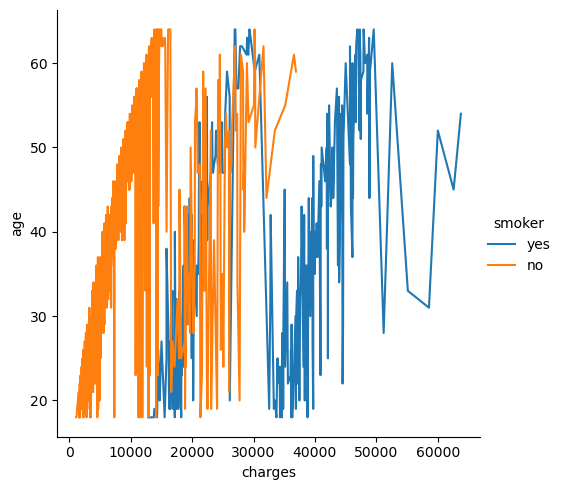

In [21]:
sns.relplot(data = df , y = "age" , x = "charges" ,kind = "line" ,hue = "smoker")


In [24]:
X = df.drop("charges",axis = 1)
Y = df["charges"]
print(X.head())
print(Y.head())

   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [25]:
X["sex"] = X["sex"].map({"female": 0, "male": 1})
X["smoker"]=X["smoker"].map({"yes":1 , "no":0})
X =pd.get_dummies(data = X , columns=["region"] , drop_first = True , dtype=int )
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,0,0,1
1,18,1,33.770,1,0,0,1,0
2,28,1,33.000,3,0,0,1,0
3,33,1,22.705,0,0,1,0,0
4,32,1,28.880,0,0,1,0,0


In [26]:
X["age_smoker"] = X["smoker"]*X["age"]
X["bmi_smoker"] = X["smoker"]*X["bmi"]
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,age_smoker,bmi_smoker
0,19,0,27.900,0,1,0,0,1,19,27.9
1,18,1,33.770,1,0,0,1,0,0,0.0
2,28,1,33.000,3,0,0,1,0,0,0.0
3,33,1,22.705,0,0,1,0,0,0,0.0
4,32,1,28.880,0,0,1,0,0,0,0.0


In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
x_train ,  x_test, y_train , y_test = train_test_split(X , Y , test_size = .20 , random_state = 101 )

In [41]:
model = LinearRegression()


In [42]:
model.fit(x_train,y_train)

LinearRegression()

In [43]:
y_pred = model.predict(x_test)

In [59]:
from sklearn.metrics import root_mean_squared_error , r2_score
RMSE = root_mean_squared_error(y_test , y_pred)
r2 = r2_score(y_test , y_pred)
print(f"Mean Squared Error is : {RMSE}")
print(f"r squeare is : {r2}")

Mean Squared Error is : 4538.42368678951
r squeare is : 0.8540343168129704


In [60]:
##LascoCV
from sklearn.linear_model import LassoCV
a=[0.001 ,0.1 , 1,2,5,10,20,50,100]
lasso_cv_model = LassoCV(
    alphas = a,
     max_iter=1000,
    cv = 5,
    random_state = 101
)
lasso_cv_model.fit(x_train, y_train)

print("best alpha: ", lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("mse = ", mse)
print("s2 = ", r2)


best alpha:  2.0
mse =  20597289.560812082
s2 =  0.8540343168129704


In [61]:
from sklearn.linear_model import LassoCV

# Do NOT pass the 'alphas' argument
lasso_cv_model = LassoCV(
    n_alphas=100,      # Number of alphas to automatically generate (default is 100)
    max_iter=10000,    # Higher max_iter helps convergence across automatic grids
    cv=5,
    random_state=101
)

lasso_cv_model.fit(x_train, y_train)

print("Best automatically chosen alpha:", lasso_cv_model.alpha_)

Best automatically chosen alpha: 162.0803464087139


In [58]:
import pandas as pd

# Combine feature names and their Lasso coefficients
coef_df = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': lasso_cv_model.coef_
})

# Filter dropped vs. kept features
dropped_features = coef_df[coef_df['Coefficient'] == 0]
kept_features = coef_df[coef_df['Coefficient'] != 0]

print("--- DROPPED FEATURES (Coeff = 0) ---")
print(dropped_features)

print("\n--- KEPT FEATURES ---")
print(kept_features)

--- DROPPED FEATURES (Coeff = 0) ---
Empty DataFrame
Columns: [Feature, Coefficient]
Index: []

--- KEPT FEATURES ---
            Feature   Coefficient
0               age    258.919208
1               sex   -440.619219
2               bmi     40.569137
3          children    490.091222
4            smoker -19552.444700
5  region_northwest   -216.446670
6  region_southeast  -1029.593515
7  region_southwest  -1201.303825
8        age_smoker    -17.687346
9        bmi_smoker   1431.170393
